# Netflix Original Films & IMDb Scores - Exploratory Data Analysis (EDA)

This dataset covers Netflix Original films released up to June 1, 2021, including documentaries and stand-up comedy specials. It combines information collected from Wikipedia with IMDb ratings to provide an overview of Netflix's original content and its audience reception 

The dataset includes the following attributes:

- Title: Name of the film or special.

- Genre: Film category or classification.

- Premiere Date: Original release date.

- Runtime: Duration of the film in minutes.

- IMDb Score: Audience rating based on IMDb user reviews.

- Languages: Languages available in the production.

This dataset offers an opportunity to explore trends in Netflix's original productions, analyze genre distributions, examine IMDb rating patterns, and investigate relationships between film duration, release dates, languages, and audience rating

## This Colab Notebook Covers the Following Questions:

- Which languages are most commonly used in long-running Netflix original films? Analyze and visualize the results.

- Analyze and visualize the IMDb scores of documentaries released between January 2019 and June 2020.

- Which genre has the highest average IMDb rating among English-language films?

- What is the average runtime of Hindi-language films?

- How many unique genres are included in the dataset? Identify and visualize them.

- What are the three most frequently represented languages in the dataset?

- Identify the top 10 movies with the highest IMDb ratings.

- Is there a relationship between IMDb scores and movie runtimes? Analyze and visualize the correlation.

- Determine the top 10 genres based on their average IMDb scores.

- Which 10 movies have the longest runtimes? Visualize the results.



In [93]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="darkgrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"


# ============================================================
# 2. LOAD DATASET
# ============================================================



df = pd.read_csv('NetflixOriginals.csv', encoding='ISO-8859-1')


print("Dataset successfully loaded!")
print(f"Dataset shape: {df.shape}")

df.head() 

Dataset successfully loaded!
Dataset shape: (584, 6)


,Title,Genre,Premiere,Runtime,IMDB Score,Language
0,Enter the Anime,Documentary,"August 5, 2019",58,2.5,English/Japanese
1,Dark Forces,Thriller,"August 21, 2020",81,2.6,Spanish
2,The App,Science fiction/Drama,"December 26, 2019",79,2.6,Italian
3,The Open House,Horror thriller,"January 19, 2018",94,3.2,English
4,Kaali Khuhi,Mystery,"October 30, 2020",90,3.4,Hindi


# Initial Data Exploration



In [94]:
#First 5 rows of the dataset are displayed above.
df.head(5)

,Title,Genre,Premiere,Runtime,IMDB Score,Language
0,Enter the Anime,Documentary,"August 5, 2019",58,2.5,English/Japanese
1,Dark Forces,Thriller,"August 21, 2020",81,2.6,Spanish
2,The App,Science fiction/Drama,"December 26, 2019",79,2.6,Italian
3,The Open House,Horror thriller,"January 19, 2018",94,3.2,English
4,Kaali Khuhi,Mystery,"October 30, 2020",90,3.4,Hindi


In [95]:
# Last 5 rows of the dataset are displayed below.
df.tail(5)

,Title,Genre,Premiere,Runtime,IMDB Score,Language
579,Taylor Swift: Reputation Stadium Tour,Concert Film,"December 31, 2018",125,8.4,English
580,Winter on Fire: Ukraine's Fight for Freedom,Documentary,"October 9, 2015",91,8.4,English/Ukranian/Russian
581,Springsteen on Broadway,One-man show,"December 16, 2018",153,8.5,English
582,Emicida: AmarElo - It's All For Yesterday,Documentary,"December 8, 2020",89,8.6,Portuguese
583,David Attenborough: A Life on Our Planet,Documentary,"October 4, 2020",83,9.0,English


In [96]:
# Dataset shape 

print('Number of rows in the dataset: ' ,df.shape[0])
print( 'Number of columns in the dataset: ', df.shape[1])

Number of rows in the dataset:  584
Number of columns in the dataset:  6


In [97]:
# Column names in the dataset are displayed below.
print('Column names in the dataset: ', df.columns.tolist())

Column names in the dataset:  ['Title', 'Genre', 'Premiere', 'Runtime', 'IMDB Score', 'Language']


In [98]:
# Datatypes of each column in the dataset are displayed below.
print('Datatypes of each column in the dataset: ' )
display(df.dtypes)

Datatypes of each column in the dataset: 


Title          object
Genre          object
Premiere       object
Runtime         int64
IMDB Score    float64
Language       object
dtype: object

In [99]:
# General information about the dataset is displayed below.
print('General information about the dataset: ')
display(df.info())

General information about the dataset: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584 entries, 0 to 583
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Title       584 non-null    object 
 1   Genre       584 non-null    object 
 2   Premiere    584 non-null    object 
 3   Runtime     584 non-null    int64  
 4   IMDB Score  584 non-null    float64
 5   Language    584 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 27.5+ KB


None

In [100]:
# Statistical summary of the dataset is displayed below.
df.describe(include='all')

,Title,Genre,Premiere,Runtime,IMDB Score,Language
count,584,584,584,584.000000,584.000000,584
unique,584,115,390,NaN,NaN,38
top,Enter the Anime,Documentary,"October 2, 2020",NaN,NaN,English
freq,1,159,6,NaN,NaN,401
mean,NaN,NaN,NaN,93.577055,6.271747,NaN
std,NaN,NaN,NaN,27.761683,0.979256,NaN
min,NaN,NaN,NaN,4.000000,2.500000,NaN
25%,NaN,NaN,NaN,86.000000,5.700000,NaN
50%,NaN,NaN,NaN,97.000000,6.350000,NaN
75%,NaN,NaN,NaN,108.000000,7.000000,NaN


# Missing values 

In [101]:
missing_values = pd.DataFrame(
    {
        "Missing Values" : df.isnull().sum(), 
        "Percentage of Missing Values" : (df.isnull().sum() / len(df)) * 100
    }
)
missing_values

,Missing Values,Percentage of Missing Values
Title,0,0.0
Genre,0,0.0
Premiere,0,0.0
Runtime,0,0.0
IMDB Score,0,0.0
Language,0,0.0


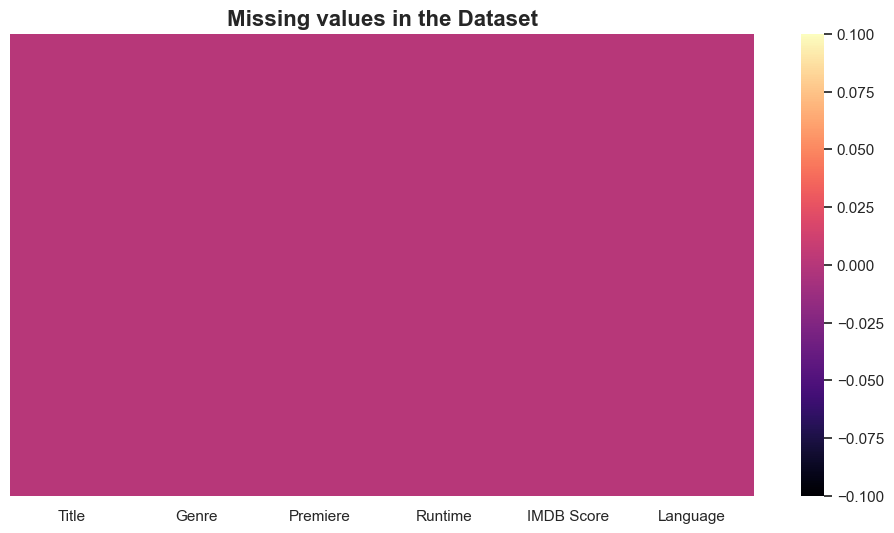

In [102]:
# Visualize missing values 
plt.figure(figsize=(12,6))

sns.heatmap(
    df.isnull(), 
    cbar=True,
    cmap='magma',
    yticklabels=False
)

plt.title('Missing values in the Dataset', fontsize=16, fontweight='bold')
plt.show()

In [103]:
# Duplicate values in the dataset are displayed below.

print('Number of duplicate values ', df.duplicated().sum() )

# Duplicate movie titles 
print("Number of duplicated titles: ", df['Title'].duplicated().sum())

Number of duplicate values  0
Number of duplicated titles:  0


# Data Cleaning

In [104]:
# Remove unnecessary spaces from column names 
df.columns = df.columns.str.strip()

# Remove unnecessary spaces from text columns
text_columns = df.select_dtypes(include=['object']).columns
for col in text_columns:
    df[col] = df[col].str.strip()   



# Convert Premiere into datetime format
df['Premiere'] = pd.to_datetime(df["Premiere"], errors='coerce')

# Convert numeric columns 
df['Runtime'] = pd.to_numeric(df['Runtime'], errors='coerce')

df['IMDB Score'] = pd.to_numeric(df['IMDB Score'], errors='coerce')



# 4. Exploratory Data Analysis – 10 Business Questions


## Which languages are most commonly used in long-running Netflix original films? Analyze and visualize the results.

In [105]:
long_running_films = df[df['Runtime'] > 120] 

language_counts = long_running_films['Language'].value_counts()

language_counts.head(10)

Language
English                 46
Hindi                    8
Korean                   3
Japanese                 2
Marathi                  2
Spanish                  2
Indonesian               1
Khmer/English/French     1
Portuguese               1
English/Korean           1
Name: count, dtype: int64

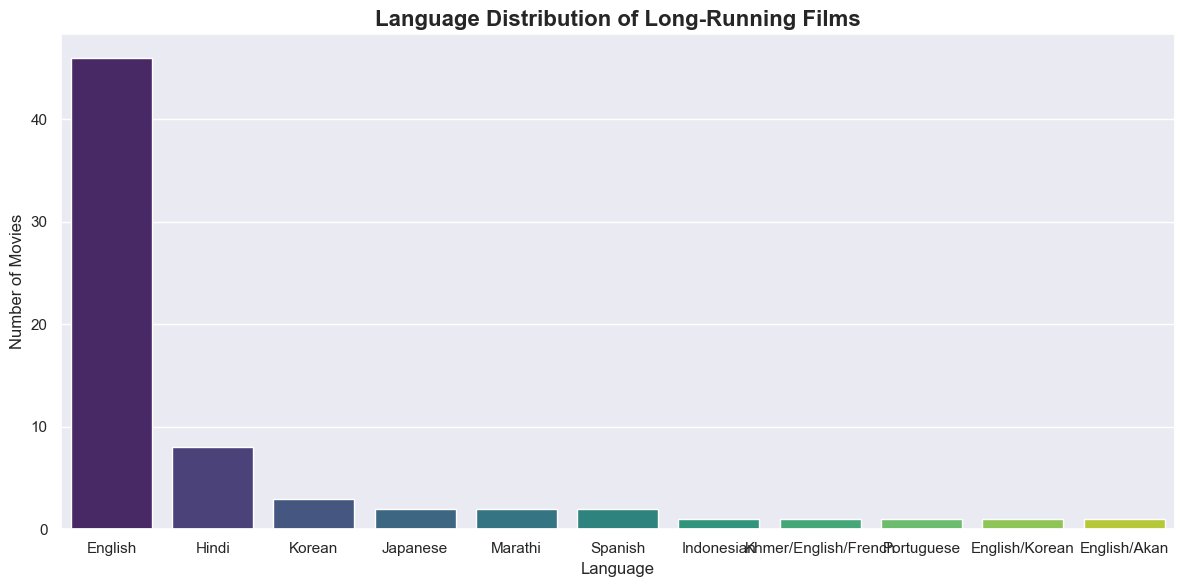

In [106]:
# Visualize language distribution of long-running films
plt.figure(figsize=(12, 6))

sns.barplot(
    x=language_counts.index,    
    y=language_counts.values,
    palette='viridis'   
)

plt.title('Language Distribution of Long-Running Films', fontsize=16, fontweight='bold')
plt.xlabel('Language', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)

plt.tight_layout()
plt.show()

## Question 2. Analyze and visualize the IMDb scores of documentaries released between January 2019 and June 2020.

In [107]:
documentary_df = df[
    (df['Genre'].str.contains('Documentary', case=False, na=False)) &
    (df['Premiere'] >= '2019-01-01') &
    (df["Premiere"] <= '2020-07-01') ].copy()



documentary_df = documentary_df.sort_values(by='Premiere', ascending=True)

documentary_df.head(10)

,Title,Genre,Premiere,Runtime,IMDB Score,Language
510,ReMastered: Massacre at the Stadium,Documentary,2019-01-11,64,7.3,English/Spanish
482,Fyre: The Greatest Party That Never Happened,Documentary,2019-01-18,97,7.2,English
511,ReMastered: The Two Killings of Sam Cooke,Documentary,2019-02-08,64,7.3,English
524,Period. End of Sentence.,Documentary,2019-02-12,26,7.4,English/Hindi
324,Antoine Griezmann: The Making of a Legend,Documentary,2019-03-21,60,6.5,French
444,ReMastered: The Miami Showband Massacre,Documentary,2019-03-22,70,7.0,English
286,The Legend of Cocaine Island,Documentary,2019-03-29,87,6.3,English
536,Homecoming: A Film by Beyonce,Documentary,2019-04-17,137,7.5,English
554,Brene Brown: The Call to Courage,Documentary,2019-04-19,76,7.7,English
462,Grass Is Greener,Documentary,2019-04-20,97,7.1,English



Average IMDB Score: 6.82
Number of movies: 52


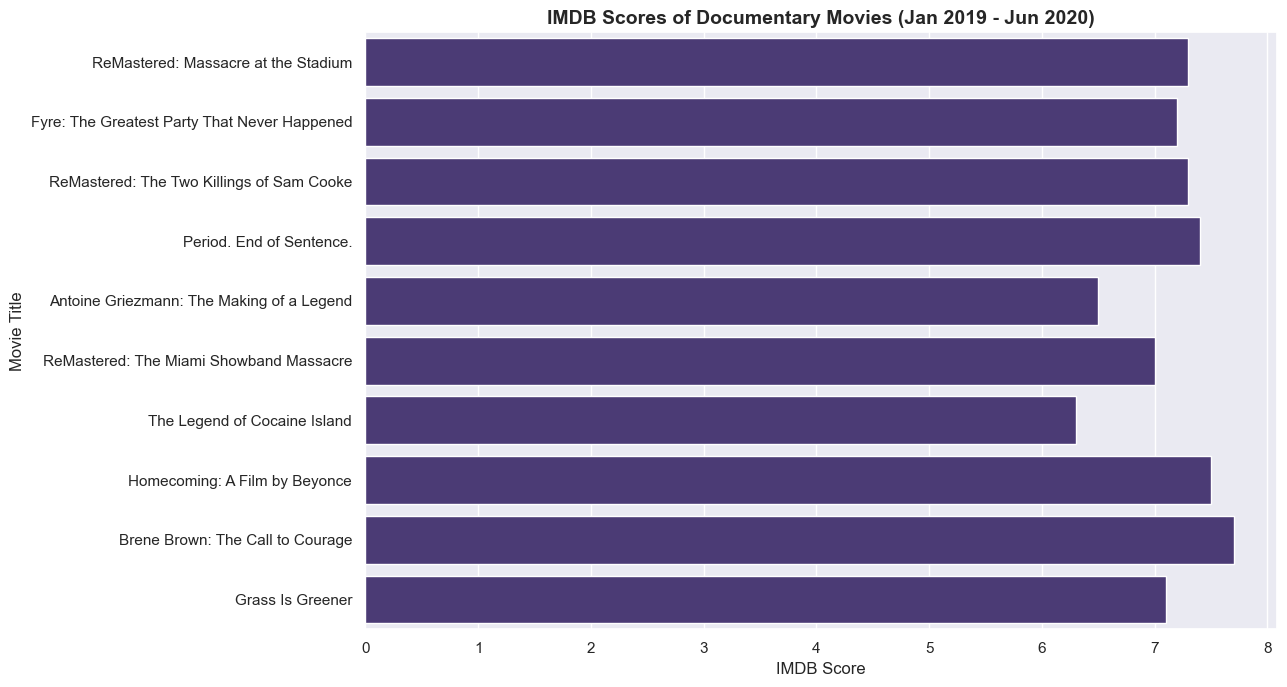

In [108]:
#Visualization 

print("\nAverage IMDB Score:",
      round(documentary_df["IMDB Score"].mean(), 2))

print("Number of movies:", len(documentary_df))


# Visualization

plt.figure(figsize=(13, 7))

sns.barplot(
    data=documentary_df.head(10),
    x="IMDB Score",
    y="Title"
)

plt.title("IMDB Scores of Documentary Movies (Jan 2019 - Jun 2020)")
plt.xlabel("IMDB Score")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()

## Question 3. Which genre has the highest average IMDb rating among English-language films?

In [109]:
english_movies=df[df['Language'].str.contains('English', case=False, na=False)]


english_genre_scores = (
    english_movies.groupby('Genre').agg(
        Average_IMDB_Score=('IMDB Score', 'mean'), 
        Movie_Count=('Title', 'count')
    ).sort_values(by='Average_IMDB_Score', ascending=False)
)


# Best Genre 
best_english_genre = english_genre_scores.iloc[0]
best_english_genre

Average_IMDB_Score    8.2
Movie_Count           1.0
Name: Animation/Christmas/Comedy/Adventure, dtype: float64

In [110]:
# Visualization

top_english_genres = english_genre_scores.head(10).reset_index()

top_english_genres 

,Genre,Average_IMDB_Score,Movie_Count
0,Animation/Christmas/Comedy/Adventure,8.200000,1
1,Musical / Short,7.700000,1
2,Concert Film,7.633333,6
3,Animation / Science Fiction,7.500000,1
4,Action-adventure,7.300000,1
5,Drama-Comedy,7.200000,1
6,Historical drama,7.200000,1
7,Making-of,7.200000,1
8,One-man show,7.133333,3
9,Animation / Short,7.125000,4


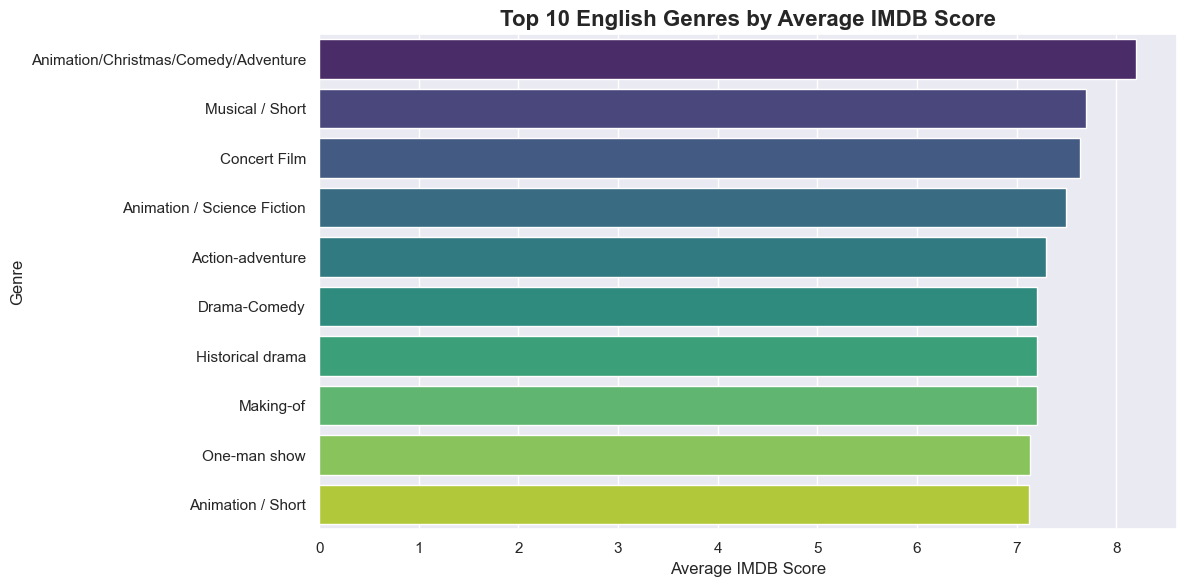

In [111]:
plt.figure(figsize=(12, 6))

sns.barplot(data=top_english_genres, x='Average_IMDB_Score', y='Genre', palette='viridis')

plt.title('Top 10 English Genres by Average IMDB Score', fontsize=16, fontweight='bold')

plt.xlabel('Average IMDB Score', fontsize=12)

plt.ylabel('Genre', fontsize=12)

plt.tight_layout()
plt.show()

## Question 4. What is the average runtime of Hindi-language films?

In [112]:
hindi_movies = df[
    df['Language'].str.contains('Hindi', case=False, na=False)
]

average_hindi_runtime = hindi_movies['Runtime'].mean()
print(f"Average Runtime of Hindi Movies: {round(average_hindi_runtime,2)}")

Average Runtime of Hindi Movies: 111.03


## Question 5. How many unique genres are included in the dataset? Identify and visualize them.

In [113]:
genre_counts = df['Genre'].value_counts()
unique_genres = df['Genre'].nunique()
genre_counts = genre_counts.head(10)
print('Number of unique genres: ', unique_genres)


Number of unique genres:  115


Text(0, 0.5, 'Genre')

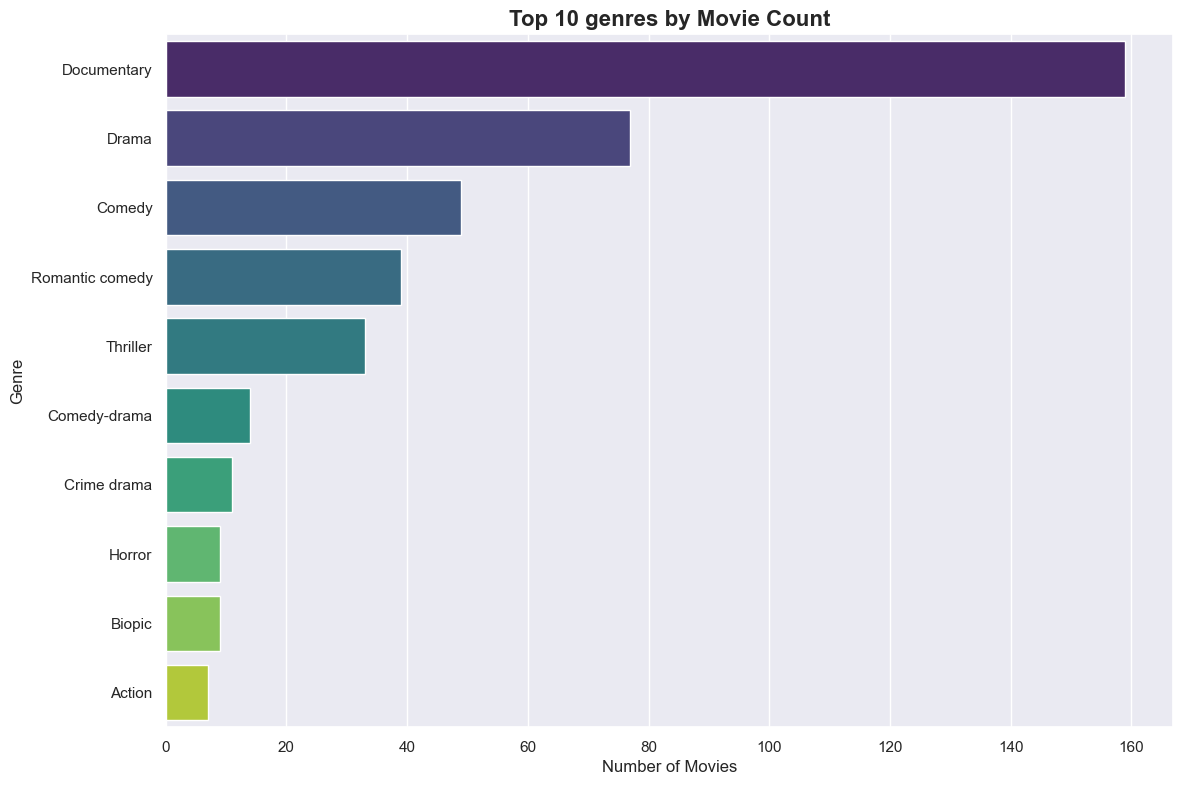

In [114]:
# Visualization 

plt.figure(figsize=(13, 9))

sns.barplot(
    x=genre_counts.values, 
    y=genre_counts.index, 
    palette='viridis'
)

plt.title("Top 10 genres by Movie Count", fontsize=16, fontweight='bold')
plt.xlabel("Number of Movies", fontsize=12)
plt.ylabel("Genre", fontsize=12)    


## Question 6. What are the three most frequently represented languages in the dataset?

In [115]:
top_3_languages=df['Language'].value_counts().head(3)

print('Top 3 most frequent languages in the dataset: ', top_3_languages)

Top 3 most frequent languages in the dataset:  Language
English    401
Hindi       33
Spanish     31
Name: count, dtype: int64


Text(0, 0.5, 'Language')

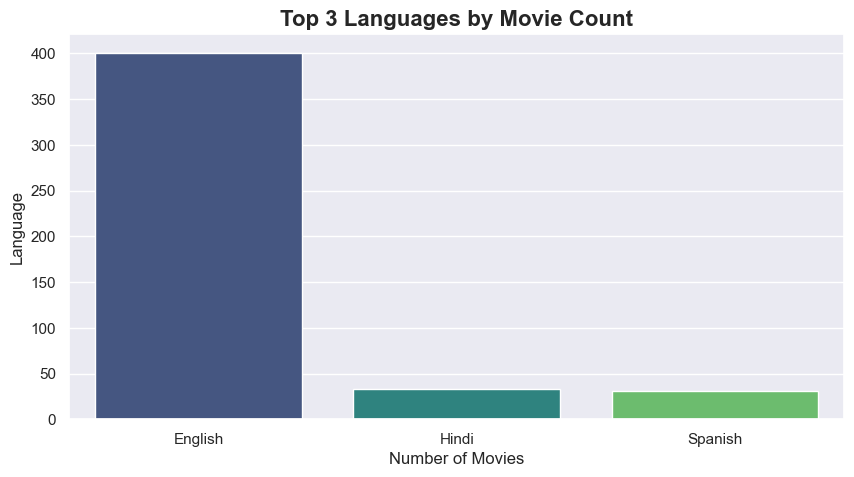

In [116]:
# Visualization 

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_3_languages.index, 
    y=top_3_languages.values, 
    palette='viridis'
)
plt.title("Top 3 Languages by Movie Count", fontsize=16, fontweight='bold')
plt.xlabel("Number of Movies", fontsize=12)
plt.ylabel("Language", fontsize=12)    

## Question 7. Identify the top 10 movies with the highest IMDb ratings.


In [117]:

top_10_movies = df.nlargest(10, 'IMDB Score')[['Title', 'IMDB Score']]

print("Top 10 Movies With IMDB Ratings:", top_10_movies.reset_index(drop=True))

Top 10 Movies With IMDB Ratings:                                          Title  IMDB Score
0     David Attenborough: A Life on Our Planet         9.0
1    Emicida: AmarElo - It's All For Yesterday         8.6
2                      Springsteen on Broadway         8.5
3   Ben Platt: Live from Radio City Music Hall         8.4
4        Taylor Swift: Reputation Stadium Tour         8.4
5  Winter on Fire: Ukraine's Fight for Freedom         8.4
6                       Cuba and the Cameraman         8.3
7                       Dancing with the Birds         8.3
8                                         13th         8.2
9            Disclosure: Trans Lives on Screen         8.2


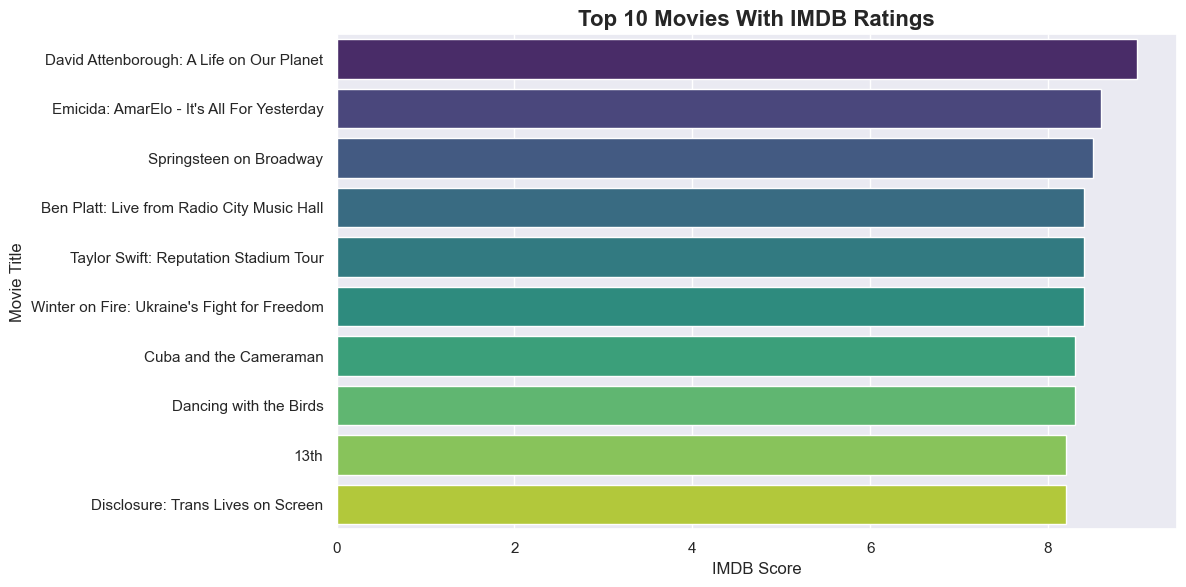

In [118]:
# Visualization 

plt.figure(figsize=(12, 6))

sns.barplot( 
    x = top_10_movies['IMDB Score'], 
    y = top_10_movies['Title'],
    palette='viridis'
)

plt.title("Top 10 Movies With IMDB Ratings", fontsize=16, fontweight='bold')
plt.xlabel("IMDB Score", fontsize=12)
plt.ylabel("Movie Title", fontsize=12)

plt.tight_layout()
plt.show()  


## Question 8. Is there a relationship between IMDb scores and movie runtimes? Analyze and visualize the correlation.

In [119]:
pearson_correlation = df["IMDB Score"].corr(
    df["Runtime"],
    method="pearson"
)

spearman_correlation = df["IMDB Score"].corr(
    df["Runtime"],  
    method="spearman"
)

print('pearson_correlation: ', round(pearson_correlation, 2))
print('spearman_correlation: ', round(spearman_correlation, 2))   


if abs(correlation) < 0.1:
    print("There is almost no linear correlation.")
elif correlation < 0:
    print("There is a negative correlation.")
elif correlation < 0.5:
    print("There is a weak positive correlation.")
else:
    print("There is a moderate or strong positive correlation.") 

    


pearson_correlation:  -0.04
spearman_correlation:  -0.02
There is almost no linear correlation.


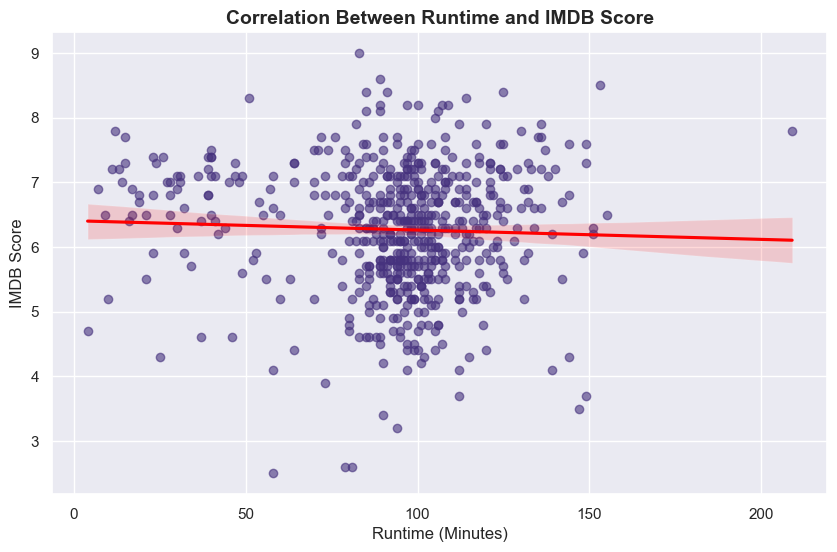

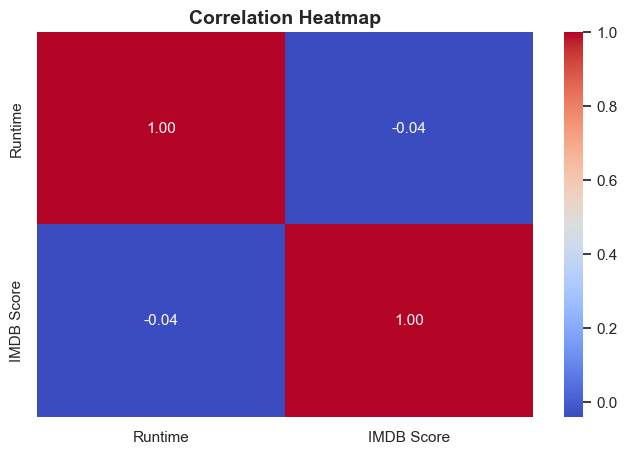

In [120]:
# Visualization

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Runtime",
    y="IMDB Score",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Correlation Between Runtime and IMDB Score")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("IMDB Score")

plt.show()


# Correlation heatmap

plt.figure(figsize=(8, 5))

correlation_matrix = df[
    ["Runtime", "IMDB Score"]
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Determine the top 10 genres based on their average IMDb scores.

In [121]:
genre_imdb = (
    df.groupby("Genre")
    .agg(
        Average_IMDB=("IMDB Score", "mean"),
        Movie_Count=("Title", "count")
    )
)
genre_imdb_filtered = genre_imdb[
    genre_imdb['Movie_Count'] >= 5
]

top_10_genres = genre_imdb_filtered.sort_values(by='Average_IMDB', ascending=False).head(10)

print("Top 10 Genres by Average IMDB Score (with at least 5 movies):")
print(top_10_genres.reset_index())

Top 10 Genres by Average IMDB Score (with at least 5 movies):
                   Genre  Average_IMDB  Movie_Count
0           Concert Film      7.633333            6
1            Documentary      6.936478          159
2  Aftershow / Interview      6.750000            6
3            Crime drama      6.745455           11
4              Animation      6.560000            5
5                Romance      6.500000            6
6                 Biopic      6.400000            9
7                  Drama      6.342857           77
8           Comedy-drama      6.214286           14
9         Romantic drama      5.900000            5


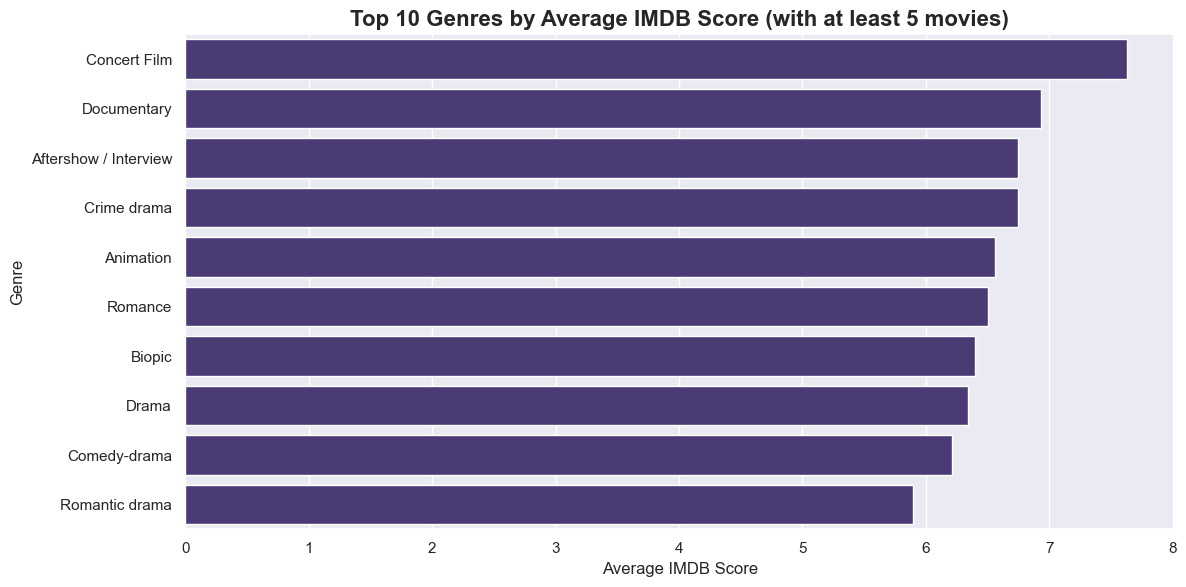

In [122]:
# visualization 

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_genres.reset_index(),
    x='Average_IMDB',
    y='Genre',
)

plt.title("Top 10 Genres by Average IMDB Score (with at least 5 movies)", fontsize=16, fontweight='bold')   
plt.xlabel("Average IMDB Score", fontsize=12)
plt.ylabel("Genre", fontsize=12)

plt.tight_layout()
plt.show()

## Question 10. Which 10 movies have the longest runtimes? Visualize the results.

In [123]:
top_10_runtime = df.nlargest(
    10,
    "Runtime"
)[
    ["Title", "Genre", "Runtime", "IMDB Score"]
]

print("Top 10 Movies with Highest Runtime:")

display(top_10_runtime)


Top 10 Movies with Highest Runtime:


,Title,Genre,Runtime,IMDB Score
561,The Irishman,Crime drama,209,7.8
328,Da 5 Bloods,War drama,155,6.5
581,Springsteen on Broadway,One-man show,153,8.5
247,Citation,Drama,151,6.2
284,The Forest of Love,Drama,151,6.3
7,The Last Days of American Crime,Heist film/Thriller,149,3.7
509,Raat Akeli Hai,Thriller,149,7.3
543,Ludo,Anthology/Dark comedy,149,7.6
194,Army of the Dead,Zombie/Heist,148,5.9
5,Drive,Action,147,3.5


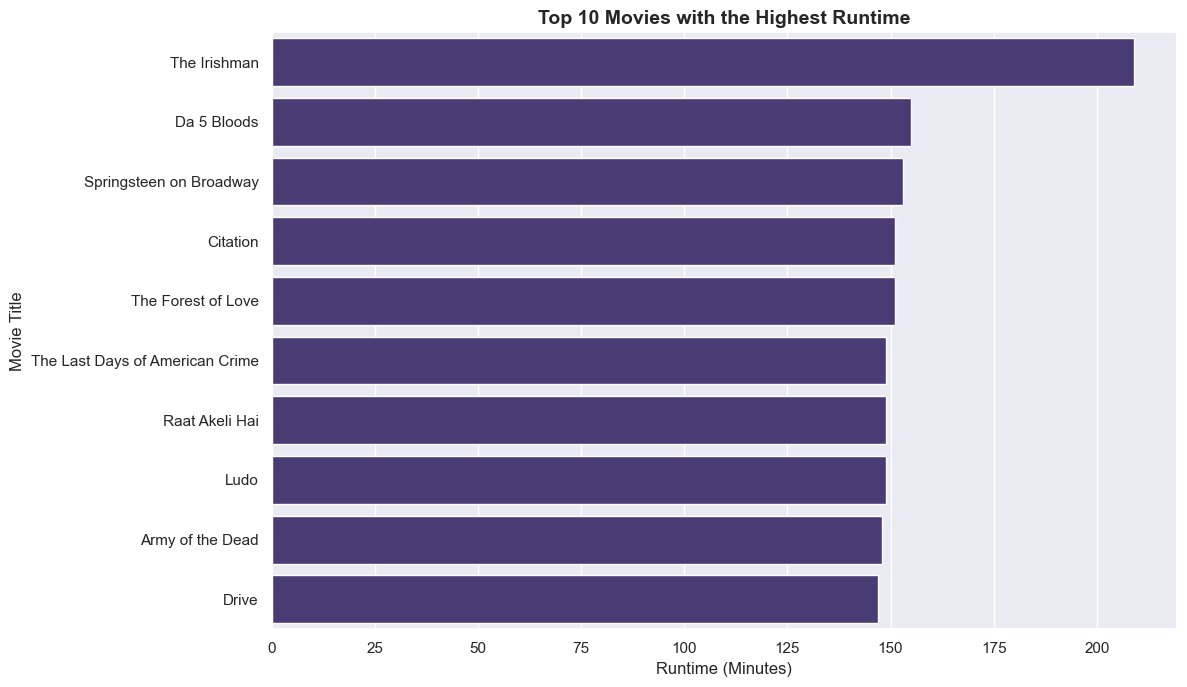

In [124]:
# Visualization

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_runtime,
    x="Runtime",
    y="Title"
)

plt.title("Top 10 Movies with the Highest Runtime")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()